In [1]:
import pandas as pd

import os

DATA_PATH = 'data\\nutrition'

dish_df = pd.read_csv(os.path.join(DATA_PATH, 'dish.csv'))
ingredients_df = pd.read_csv(os.path.join(DATA_PATH, 'ingredients.csv'))

# Этап 1. EDA

In [2]:
dish_df.sample(10)

,dish_id,total_calories,total_mass,ingredients,split
2584,dish_1558026684,24.139999,71.0,ingr_0000000037,train
844,dish_1561060531,162.078995,177.0,ingr_0000000525;ingr_0000000016;ingr_000000001...,train
1980,dish_1567526785,378.250000,539.0,ingr_0000000128;ingr_0000000161;ingr_000000043...,train
1094,dish_1559925174,88.349998,155.0,ingr_0000000013,train
980,dish_1562775373,329.080017,148.0,ingr_0000000004;ingr_0000000008,train
1255,dish_1558113477,289.050018,50.0,ingr_0000000077,test
1732,dish_1560453150,152.320267,141.0,ingr_0000000189;ingr_0000000036;ingr_000000012...,train
1957,dish_1565369938,167.709991,31.0,ingr_0000000004,train
2045,dish_1562958445,24.150000,21.0,ingr_0000000012,train
1763,dish_1558723982,294.830994,51.0,ingr_0000000077,train


In [3]:
ingredients_df.sample(10)

,id,ingr
296,297,pepperoni
138,139,egg rolls
355,356,french fries
481,482,rice
158,159,apple cider
541,542,white beans
350,351,mackerel
485,486,cakes
128,129,raisins
427,428,white wine


In [4]:
dish_df.isnull().sum()

dish_id           0
total_calories    0
total_mass        0
ingredients       0
split             0
dtype: int64

In [5]:
ingredients_df.isnull().sum()

id      0
ingr    0
dtype: int64

In [6]:
print(f"Dishes {len(dish_df)} # unique {dish_df[['dish_id']].nunique()}")
print(f"Train Dishes {len(dish_df[dish_df.split == 'train'])}")
print(f"Test Dishes {len(dish_df[dish_df.split == 'test'])}")

Dishes 3262 # unique dish_id    3262
dtype: int64
Train Dishes 2755
Test Dishes 507


In [7]:
dish_df[['total_calories', 'total_mass']].describe().round(2)

,total_calories,total_mass
count,3262.00,3262.00
mean,255.01,214.98
std,219.64,161.50
min,0.00,1.00
25%,80.11,92.00
50%,209.11,177.00
75%,375.12,305.00
max,3943.33,3051.00


In [8]:
dish_df[dish_df.total_calories < 1.0]

,dish_id,total_calories,total_mass,ingredients,split
263,dish_1557861216,0.0,1.0,ingr_0000000423,test
2652,dish_1556575700,0.0,86.0,ingr_0000000423,train


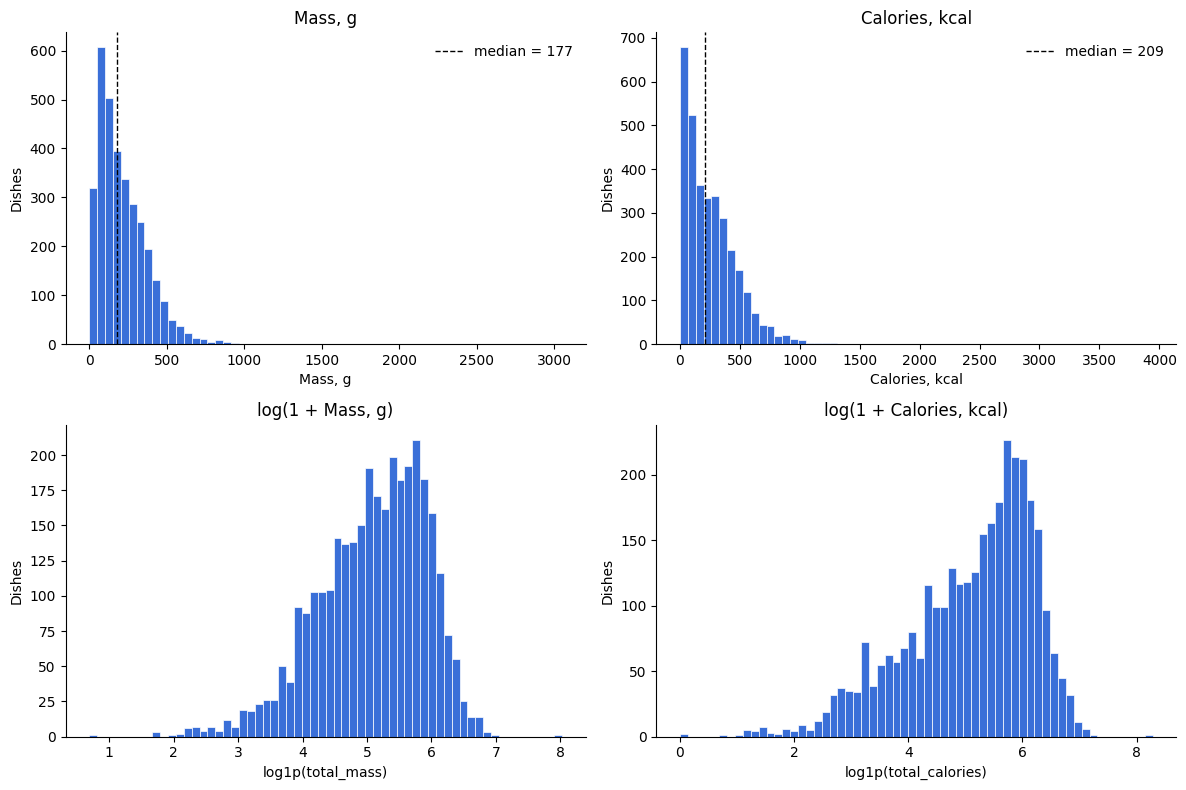

In [9]:
import numpy as np
import matplotlib.pyplot as plt

COLOR = "#3a6fd8"
cols = {"total_mass": "Mass, g", "total_calories": "Calories, kcal"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, (col, label) in enumerate(cols.items()):
    # гистограммы
    axes[0, i].hist(dish_df[col], bins=60, color=COLOR, edgecolor="white", linewidth=0.5)
    axes[0, i].axvline(dish_df[col].median(), color="black", ls="--", lw=1,
                       label=f"median = {dish_df[col].median():.0f}")
    axes[0, i].set(title=label, xlabel=label, ylabel="Dishes")
    axes[0, i].legend(frameon=False)

    # логарифмированные гистограммы, лучше видны хвосты
    axes[1, i].hist(np.log1p(dish_df[col]), bins=60, color=COLOR, edgecolor="white", linewidth=0.5)
    axes[1, i].set(title=f"log(1 + {label})", xlabel=f"log1p({col})", ylabel="Dishes")

for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

В датасете 3262 блюда: 2755 тренировочных, 507 тестовых. Распределения массы и калорийности имеют правостороннюю ассиметрию. Поэтому в качестве нормализации уместно использовать логарифмические трансформации. Посмотрим на выбросы. Также нужно проверить, что у каждого блюда есть картинка.

In [10]:
#так как распределение не нормальное, используем межквантильное расстояние
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

df = dish_df.copy()
df["kcal_per_g"] = df["total_calories"] / df["total_mass"]
df["log_cal"] = np.log1p(df["total_calories"])
df["log_mass"] = np.log1p(df["total_mass"])

#также есть проверка здравого смысла - отношение калорий к массе должно быть между 0 и 9
df["out_density"] = (df["kcal_per_g"] > 9) | (df["total_calories"] == 0)

lo, hi = iqr_bounds(df["log_cal"]);
df["out_cal"]  = ~df["log_cal"].between(lo, hi)
lo, hi = iqr_bounds(df["log_mass"]);
df["out_mass"] = ~df["log_mass"].between(lo, hi)

flags = ["out_cal", "out_mass", "out_density"]
df["n_flags"] = df[flags].sum(axis=1)
print(df[flags].sum())

out_cal        40
out_mass       36
out_density     2
dtype: int64


In [11]:
cols = ["dish_id", "split", "total_mass", "total_calories","kcal_per_g", "n_ingr"]
df["n_ingr"] = df["ingredients"].str.split(";").str.len()

df[df.n_flags > 0].sort_values(["n_flags"], ascending=False)[cols].head(30)

,dish_id,split,total_mass,total_calories,kcal_per_g,n_ingr
263,dish_1557861216,test,1.0,0.000000,0.000000,1
26,dish_1558549773,test,10.0,2.300000,0.230000,1
377,dish_1558630288,test,11.0,7.106000,0.646000,1
195,dish_1558461431,test,5.0,1.150000,0.230000,1
1508,dish_1559158425,train,13.0,2.990000,0.230000,1
1421,dish_1558641211,train,8.0,3.280000,0.410000,1
1351,dish_1558458438,train,14.0,3.220000,0.230000,1
1518,dish_1560974769,train,3051.0,3943.325195,1.292470,14
1209,dish_1558548958,train,10.0,2.300000,0.230000,1
906,dish_1558462036,train,13.0,2.990000,0.230000,1


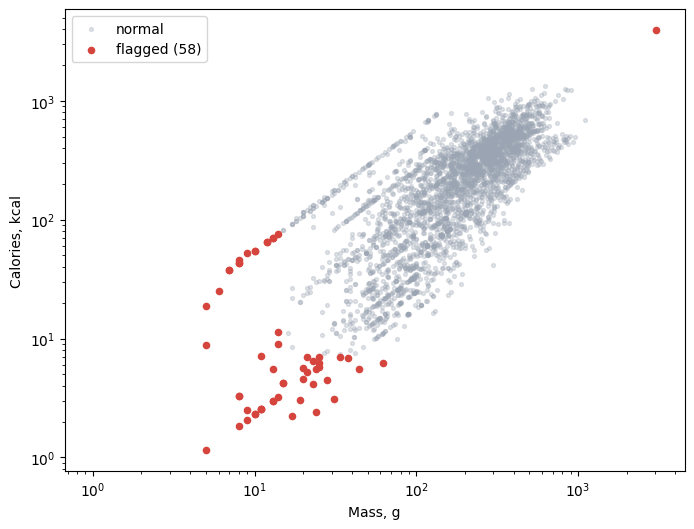

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
normal = df[df.n_flags == 0]
out = df[df.n_flags > 0]
ax.scatter(normal.total_mass, normal.total_calories, s=8, alpha=0.3, color="#9aa4b2", label="normal")
ax.scatter(out.total_mass, out.total_calories, s=20, color="#d6453d", label=f"flagged ({len(out)})")

ax.set(xscale="log", yscale="log", xlabel="Mass, g", ylabel="Calories, kcal")
ax.legend()
plt.show()


перед тем, как принимать решение об исключении выбросов, взглянем на их фотографии.

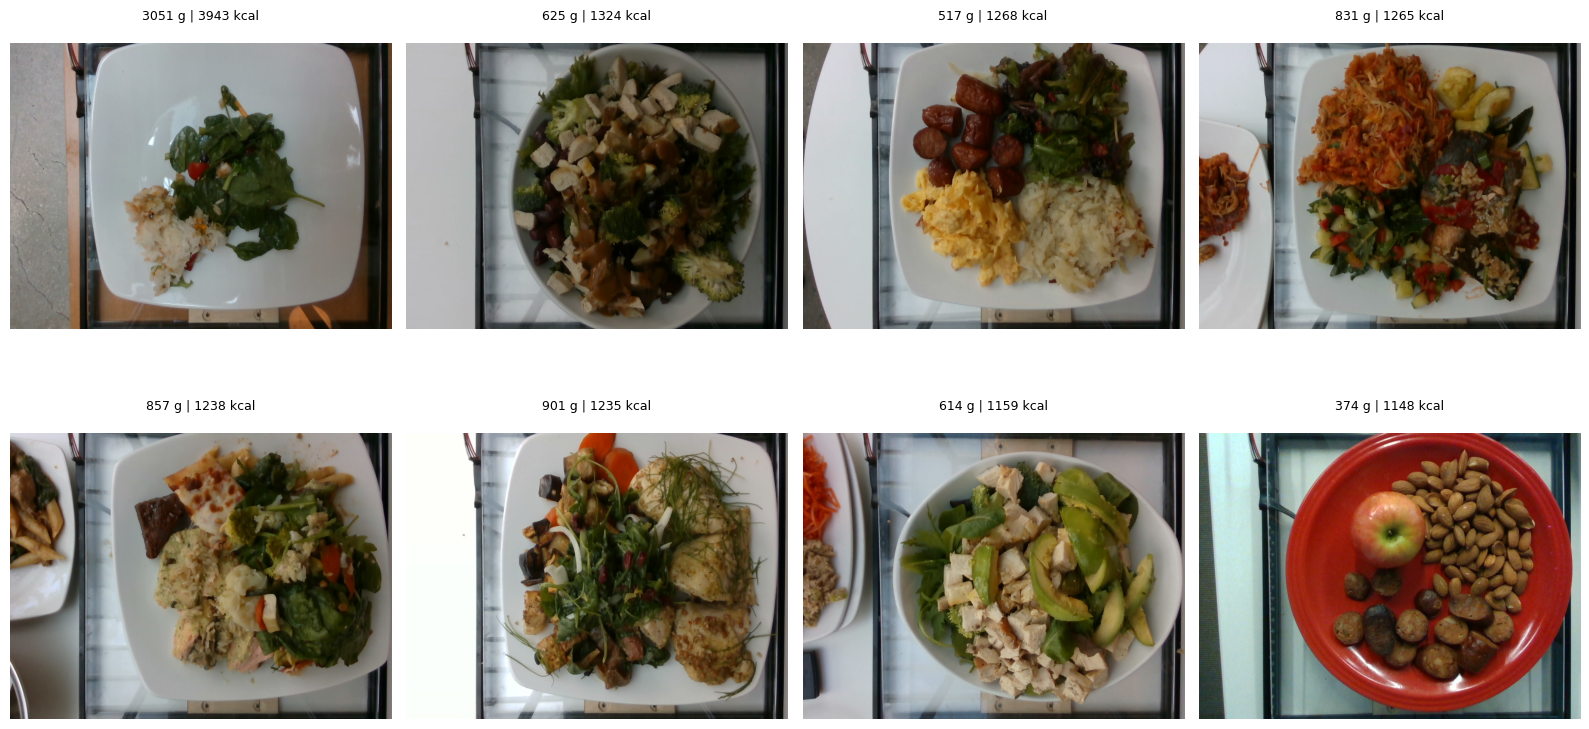

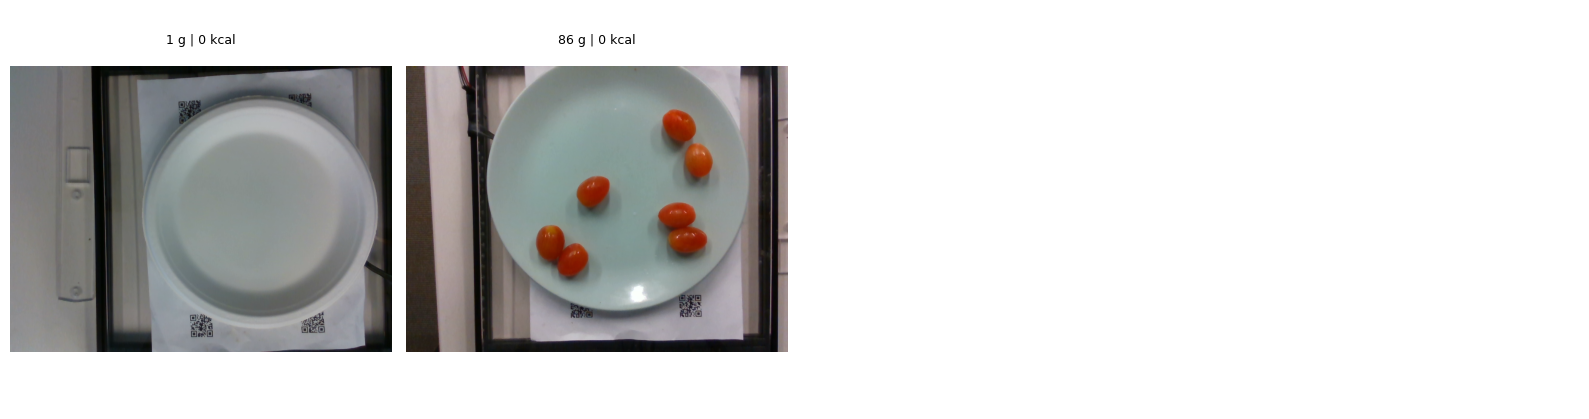

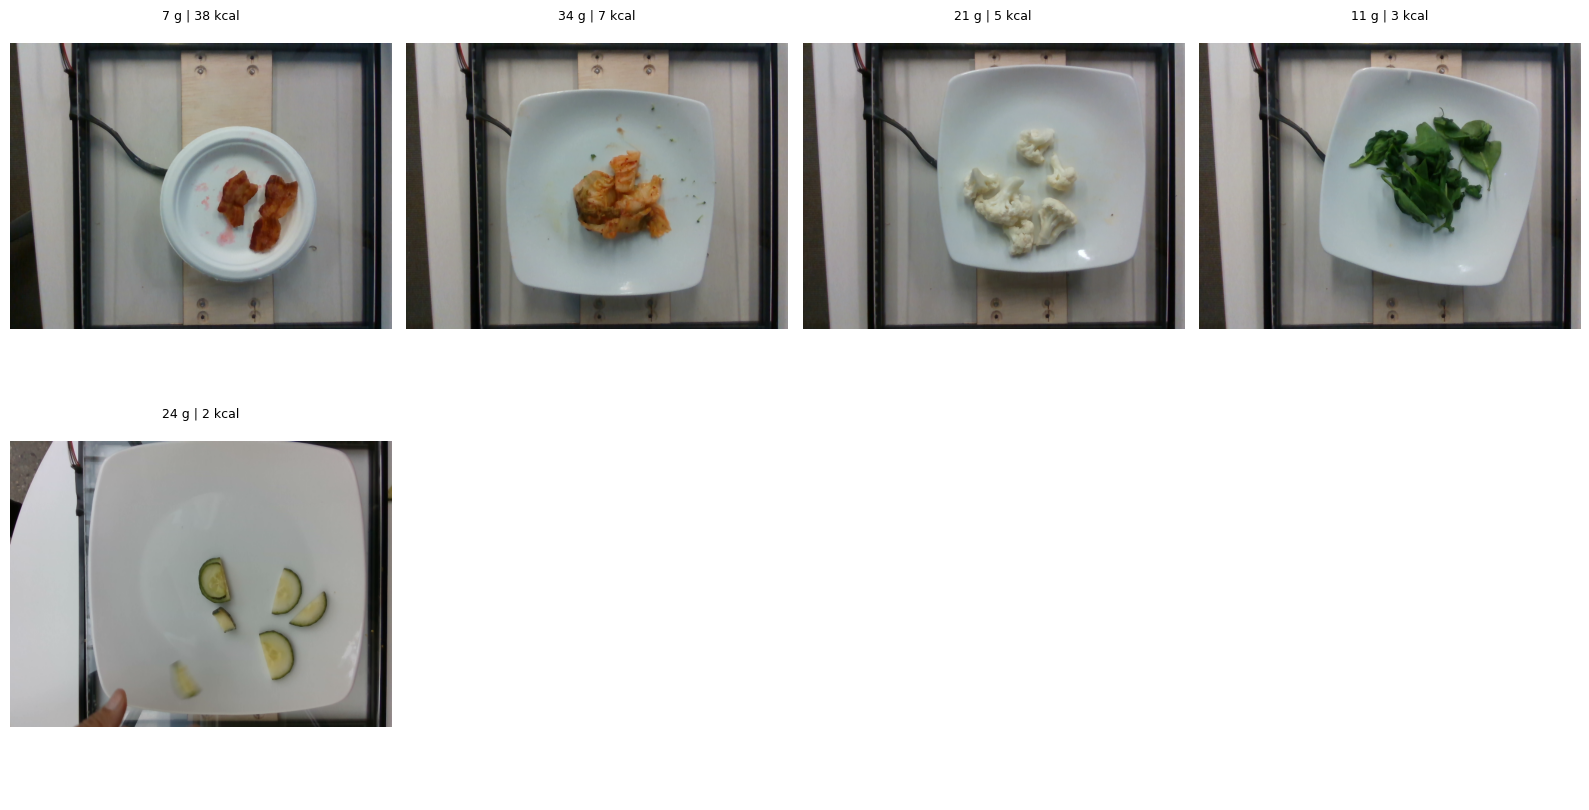

In [13]:
from PIL import Image

def show_dishes(rows, img_root=os.path.join(DATA_PATH, "images")):
    rows = rows.reset_index(drop=True)
    nrows = int(np.ceil(len(rows) / 4))
    fig, axes = plt.subplots(nrows, 4, figsize=(16, 4.3 * nrows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, r) in zip(np.ravel(axes), rows.iterrows()):
        path = os.path.join(img_root, r.dish_id, "rgb.png")
        if os.path.exists(path):
            ax.imshow(Image.open(path))
        else:
            ax.text(0.5, 0.5, "no image", ha="center")
        ax.set_title(f"{r.total_mass:.0f} g | {r.total_calories:.0f} kcal\n", fontsize=9)
    plt.tight_layout()
    plt.show()

show_dishes(df.nlargest(8, "total_calories")) # высококалорийные
show_dishes(df[df.out_density]) # невозможные
show_dishes(df[df.n_flags > 0].sample(5))


Глядя на фото, мы можем отметить, что высококалорийные блюда выглядят нажористо в большинстве своем, также среди них блюда с малой массой. Пустые тарелки также возможны. Блюдо с 86 г 0 ккал является выбросом, безкалорийных помидорок не бывает. Если что-то убирать, то лишь эту строку. Однако, используя функцию потерь, устойчивую к выбросам (MAE, Huber loss), можно вообще не чистить датасет.

In [14]:
#объединим датафрейм со словарем ингридиентов и логарифмируем массу и калорийность
ingr_map = dict(zip(ingredients_df["id"], ingredients_df["ingr"]))

dish_df["ingredients"] = dish_df["ingredients"].apply(lambda s: [ingr_map.get(int(x.replace("ingr_", ""))) for x in s.split(';')])
dish_df["ingredients"] = dish_df["ingredients"].str.join(", ")
dish_df.head()

,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,"soy sauce, garlic, white rice, parsley, onions...",test
1,dish_1561662054,419.438782,292.0,"pepper, white rice, mixed greens, garlic, soy ...",train
2,dish_1562008979,382.936646,290.0,"jalapenos, lemon juice, pork, wheat berry, cab...",test
3,dish_1560455030,20.590000,103.0,"cherry tomatoes, cucumbers, baby carrots",train
4,dish_1558372433,74.360001,143.0,deprecated,train


In [15]:
ingredients_df[ingredients_df.ingr == 'deprecated']

,id,ingr
230,231,deprecated
452,453,deprecated
457,458,deprecated
469,470,deprecated


deprecated ингридиенты заменим на 'unknown', чтобы нейросеть не искала в них смысл при встрече токена. И предсказывала калорийность лишь по картинке.

In [16]:
dish_df["ingredients"] = dish_df["ingredients"].apply(lambda s: s.replace("deprecated", ""))
dish_df.loc[dish_df["ingredients"] == "", "ingredients"] = "unknown"
dish_df.head()

,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,"soy sauce, garlic, white rice, parsley, onions...",test
1,dish_1561662054,419.438782,292.0,"pepper, white rice, mixed greens, garlic, soy ...",train
2,dish_1562008979,382.936646,290.0,"jalapenos, lemon juice, pork, wheat berry, cab...",test
3,dish_1560455030,20.590000,103.0,"cherry tomatoes, cucumbers, baby carrots",train
4,dish_1558372433,74.360001,143.0,unknown,train


In [17]:
dish_df["total_calories"] = np.log1p(dish_df["total_calories"])

In [18]:
dish_df["total_mass"] = np.log1p(dish_df["total_mass"])

In [19]:
# проверим, что у каждого блюда есть rgb.png

for _, r in dish_df.iterrows():
    path = os.path.join(DATA_PATH, "images", r.dish_id, "rgb.png")
    if not os.path.exists(path):
       print(f"No image: {r.dish_id}")

In [20]:
train_df = dish_df.copy()[dish_df.split == 'train']
train_df.drop('split', axis=1,inplace=True)
train_df.head()

,dish_id,total_calories,total_mass,ingredients
1,dish_1561662054,6.041299,5.680173,"pepper, white rice, mixed greens, garlic, soy ..."
3,dish_1560455030,3.072230,4.644391,"cherry tomatoes, cucumbers, baby carrots"
4,dish_1558372433,4.322277,4.969813,unknown
5,dish_1565640549,3.839085,4.941642,"tomatoes, cilantro, olive oil, mustard greens,..."
6,dish_1563207364,5.737443,5.605802,"scrambled eggs, yam, grapes, egg whites, olive..."


In [21]:
test_df = dish_df.copy()[dish_df.split == 'test']
test_df.drop('split', axis=1,inplace=True)
test_df.head()

,dish_id,total_calories,total_mass,ingredients
0,dish_1561662216,5.709746,5.267858,"soy sauce, garlic, white rice, parsley, onions..."
2,dish_1562008979,5.950478,5.673323,"jalapenos, lemon juice, pork, wheat berry, cab..."
16,dish_1561739238,5.617462,5.552960,"egg whites, hash browns, berries, sweet potato"
23,dish_1562691032,6.041876,6.030685,"berries, olive oil, pineapple, scrambled eggs,..."
26,dish_1558549773,1.193922,2.397895,spinach (raw)


## Видение решения

### 1. Постановка задачи

Задача - регрессия. По фото блюда и его текстовому описанию предсказать калорийность.
Архитектура - мультимодальная модель. Изображения - efficient net. Текст - bert. Затем слияние проекций модальностей в общее пространство, потом слияение проекций и MLP голова, выдающее одно число. Предсказываем `log1p(total_calories)`. Функция потерь - Huber или MAE. Обе устойчивы к оставшимся выбросам, поэтому датасет не нужно агрессивно чистить. При обучении также будет дообучать последние блоки двух под моделей. 

Бейзлайны - константа, только текст, только изображение, мультимодальная модель.

### 2. Подготовка, обогащение и аугментацияю

Маленькие порции овощей и тяжелые блюда оставляем - это реальные данные. Ингредиенты deprecated заменяем на unknown, чтобы токен не нес ложного смысла Проверяем, что у каждого блюда есть rgb.png.

Аугментации изображений: 
 - повороты на любой угол и отражения. Фото сделаны сверху, у блюда нет «верха», поэтому поворот не меняет таргет и бесплатно увеличивает выборку. 
 - Умеренное масштабирование и кроп
 - легкий colorjitter
 - небольшщой coarsedropout

Аугментации текста:
 - Перемешивание порядка ингредиентов.

### 3. метрики.

Основная - MAE в ккал. Она интерпретируема и на неё ориентируемся для early stopping и выбора лучшего чекпоинта.


# Этап 2. Реализация pipeline

In [22]:
from functools import partial

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from transformers import AutoTokenizer

from project_config import Config, DEVICE
from project_dataset import MultimodalDataset, collate_fn, get_transforms
from project_utils import train, validate, MultimodalModel, seed_everything

# в данных есть дубликаты, поэтому сплит групповой
df_train, df_val = train_test_split(train_df, test_size=0.2, random_state=42)

print(len(df_train), len(df_val))


2204 551


# Этап 3. Обучение

Baseline модели
1. Медиана калорий в train датасете
2. масса x средняя калорийность грамма
Затем мультимодальная и с выключенным текстом/изображением

In [23]:
def mae_kcal(pred_log, true_log):
    return np.abs(np.expm1(pred_log) - np.expm1(true_log)).mean()

const_pred = np.full(len(df_val), df_train["total_calories"].median())

# масса × средняя калорийность грамма в train
k = np.expm1(df_train["total_calories"]).sum() / np.expm1(df_train["total_mass"]).sum()
mass_pred = np.log1p(np.expm1(df_val["total_mass"]) * k)

baselines = {
    "Train median value val dataset": mae_kcal(const_pred, df_val["total_calories"]).item(),
    f"Mass x {k:.2f} ccal/g val dataset": mae_kcal(mass_pred, df_val["total_calories"]).item(),
}
baselines


{'Train median value val dataset': 164.20037064172723,
 'Mass x 1.17 ccal/g val dataset': 106.11910845996225}

In [24]:
runs = {
    "text + image": None,
    "только image": "image",
    "только text": "text",
}

histories = {}
for name, mask in runs.items():
    print(f"\n===== {name} =====")
    config = Config(save_path=f"best_{mask or 'multimodal'}.pth")
    histories[name] = train(config, df_train, df_val, mask=mask)


===== text + image =====


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Разморожен слой: encoder.layer.11.attention.self.query.weight
Разморожен слой: encoder.layer.11.attention.self.query.bias
Разморожен слой: encoder.layer.11.attention.self.key.weight
Разморожен слой: encoder.layer.11.attention.self.key.bias
Разморожен слой: encoder.layer.11.attention.self.value.weight
Разморожен слой: encoder.layer.11.attention.self.value.bias
Разморожен слой: encoder.layer.11.attention.output.dense.weight
Разморожен слой: encoder.layer.11.attention.output.dense.bias
Разморожен слой: encoder.layer.11.attention.output.LayerNorm.weight
Разморожен слой: encoder.layer.11.attention.output.LayerNorm.bias
Разморожен слой: encoder.layer.11.intermediate.dense.weight
Разморожен слой: encoder.layer.11.intermediate.dense.bias
Разморожен слой: encoder.layer.11.output.dense.weight
Разморожен слой: encoder.layer.11.output.dense.bias
Разморожен слой: encoder.layer.11.output.LayerNorm.weight
Разморожен слой: encoder.layer.11.output.LayerNorm.bias
Разморожен слой: blocks.6.0.conv_pw.weig

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Разморожен слой: encoder.layer.11.attention.self.query.weight
Разморожен слой: encoder.layer.11.attention.self.query.bias
Разморожен слой: encoder.layer.11.attention.self.key.weight
Разморожен слой: encoder.layer.11.attention.self.key.bias
Разморожен слой: encoder.layer.11.attention.self.value.weight
Разморожен слой: encoder.layer.11.attention.self.value.bias
Разморожен слой: encoder.layer.11.attention.output.dense.weight
Разморожен слой: encoder.layer.11.attention.output.dense.bias
Разморожен слой: encoder.layer.11.attention.output.LayerNorm.weight
Разморожен слой: encoder.layer.11.attention.output.LayerNorm.bias
Разморожен слой: encoder.layer.11.intermediate.dense.weight
Разморожен слой: encoder.layer.11.intermediate.dense.bias
Разморожен слой: encoder.layer.11.output.dense.weight
Разморожен слой: encoder.layer.11.output.dense.bias
Разморожен слой: encoder.layer.11.output.LayerNorm.weight
Разморожен слой: encoder.layer.11.output.LayerNorm.bias
Разморожен слой: blocks.6.0.conv_pw.weig

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Разморожен слой: encoder.layer.11.attention.self.query.weight
Разморожен слой: encoder.layer.11.attention.self.query.bias
Разморожен слой: encoder.layer.11.attention.self.key.weight
Разморожен слой: encoder.layer.11.attention.self.key.bias
Разморожен слой: encoder.layer.11.attention.self.value.weight
Разморожен слой: encoder.layer.11.attention.self.value.bias
Разморожен слой: encoder.layer.11.attention.output.dense.weight
Разморожен слой: encoder.layer.11.attention.output.dense.bias
Разморожен слой: encoder.layer.11.attention.output.LayerNorm.weight
Разморожен слой: encoder.layer.11.attention.output.LayerNorm.bias
Разморожен слой: encoder.layer.11.intermediate.dense.weight
Разморожен слой: encoder.layer.11.intermediate.dense.bias
Разморожен слой: encoder.layer.11.output.dense.weight
Разморожен слой: encoder.layer.11.output.dense.bias
Разморожен слой: encoder.layer.11.output.LayerNorm.weight
Разморожен слой: encoder.layer.11.output.LayerNorm.bias
Разморожен слой: blocks.6.0.conv_pw.weig

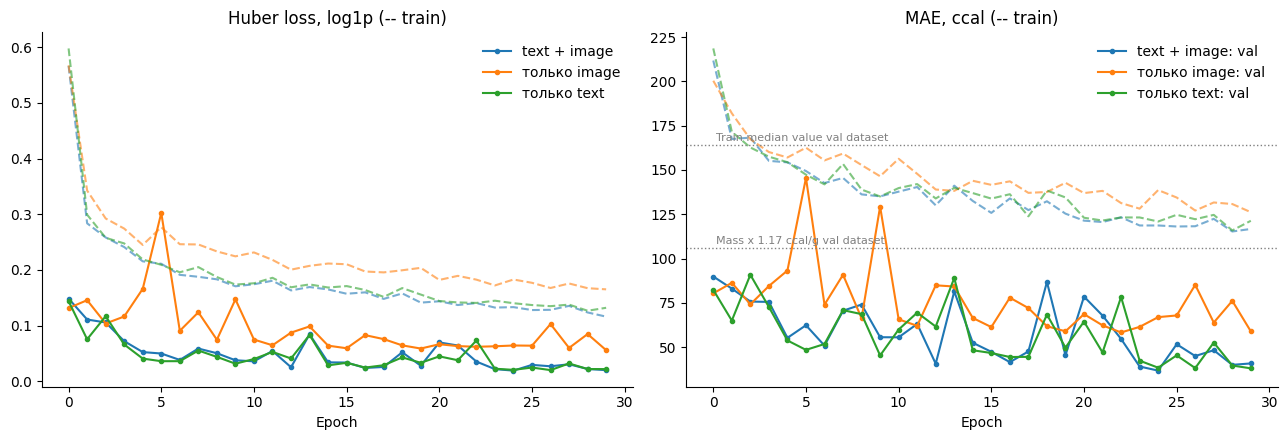

In [26]:
#кривые обучения
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in histories.items():
    line, = axes[1].plot(h["epoch"], h["val_mae"], marker="o", ms=3, label=f"{name}: val")
    axes[1].plot(h["epoch"], h["train_mae"], ls="--", color=line.get_color(), alpha=0.6)
    axes[0].plot(h["epoch"], h["val_loss"], marker="o", ms=3, color=line.get_color(), label=name)
    axes[0].plot(h["epoch"], h["train_loss"], ls="--", color=line.get_color(), alpha=0.6)

for ax, title in [(axes[0], "Huber loss, log1p (-- train)"),
                  (axes[1], "MAE, ccal (-- train)")]:
    ax.set(xlabel="Epoch", title=title)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)

for name, value in baselines.items():
    axes[1].axhline(value, color="gray", ls=":", lw=1)
    axes[1].annotate(name, (0, value), xytext=(2, 3), textcoords="offset points", fontsize=8, color="gray")
plt.tight_layout()
plt.show()


По кривым обучения видим, что разделение модальностей не ведет к приросту качества. на валидации ошибка слишком скачет от эпохе к эпохе, скачки не зависят от модальности, т.е имеется нестабильность в самой модели. Вероятно это связано с неправильно подобранными гиперпараметрами (lr головы, размер батча мал), также сама валидация на ~500 блюд ведет к раскачке метрики.

Train MAE >> Val MAE. Разрыв из-за применения аугментаций, дропаута, и усреднения MAE по всем батчам. Также, скорее всего, выбросы (3000 ккал) попали в train, либо в val оказались простые блюда.

Что касается модальностей, то почти всю работу делает текст, а картинка поверх дает мало. text+image и только text - разница в пределах шума. По сути, список ингридиентов с общей массой задает ответ, модель идет через текст.

Также сохраняются тренды к улучшению качества, что train, что val еще не сошлись.

Посмотим теперь на итоговую метрику на отложенной выборке и проанализируем ошибки предсказаний

In [28]:
def evaluate(config, df, mask=None):
    model = MultimodalModel(config).to(DEVICE)
    model.load_state_dict(torch.load(config.save_path, map_location=DEVICE))
    tokenizer = AutoTokenizer.from_pretrained(config.text_model_name)
    loader = DataLoader(MultimodalDataset(config, get_transforms(config, "val"), df, mask=mask),
                        batch_size=config.batch_size, shuffle=False,
                        collate_fn=partial(collate_fn, tokenizer=tokenizer))
    _, mae = validate(model, loader, DEVICE, nn.SmoothL1Loss())
    return mae

results = {name: mae_kcal(np.full(len(test_df), df_train["total_calories"].median()), test_df["total_calories"])
           for name in ["Константа (медиана)"]}
results[f"Масса x {k:.2f} ccal/g"] = mae_kcal(np.log1p(np.expm1(test_df["total_mass"]) * k),
                                              test_df["total_calories"])
for name, mask in runs.items():
    if name in histories:
        results[name] = evaluate(Config(save_path=f"best_{mask or 'multimodal'}.pth"), test_df, mask=mask)

pd.Series(results, name="MAE на test, ккал").round(1).to_frame()


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,"MAE на test, ккал"
Константа (медиана),167.4
Масса x 1.17 ccal/g,102.7
text + image,40.8
только image,55.1
только text,44.3


Мультимодальная архитектура дает прирост по сравнению с baseline. Есть ее схожесть лишь с текстовой моделью.

In [36]:
config = Config(save_path="best_multimodal.pth")
model = MultimodalModel(config).to(DEVICE)
model.load_state_dict(torch.load(config.save_path, map_location=DEVICE))
model.eval()

tokenizer = AutoTokenizer.from_pretrained(config.text_model_name)
loader = DataLoader(MultimodalDataset(config, get_transforms(config, "val"), test_df),
                    batch_size=config.batch_size, shuffle=False,
                    collate_fn=partial(collate_fn, tokenizer=tokenizer))

preds = []
with torch.no_grad():
    for batch in loader:
        inputs = {k: batch[k].to(DEVICE) for k in ("input_ids", "attention_mask", "image", "aux")}
        preds.append(model(**inputs).cpu())

err_df = test_df.reset_index(drop=True).copy()
err_df["total_calories"] = np.expm1(err_df["total_calories"])
err_df["total_mass"] = np.expm1(err_df["total_mass"])
err_df["pred_kcal"] = np.expm1(torch.cat(preds).numpy()).clip(min=0)
err_df["abs_err"] = (err_df["pred_kcal"] - err_df["total_calories"]).abs()

# ошибка по бинам калорийности
err_df.groupby(pd.qcut(err_df["total_calories"], 5))["abs_err"].mean().round(1)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
C:\Users\bimbo\AppData\Local\Temp\ipykernel_37908\1204136503.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt t

total_calories
(-0.001, 60.972]        4.0
(60.972, 147.538]      14.9
(147.538, 282.36]      34.4
(282.36, 417.959]      51.9
(417.959, 1050.511]    98.5
Name: abs_err, dtype: float64

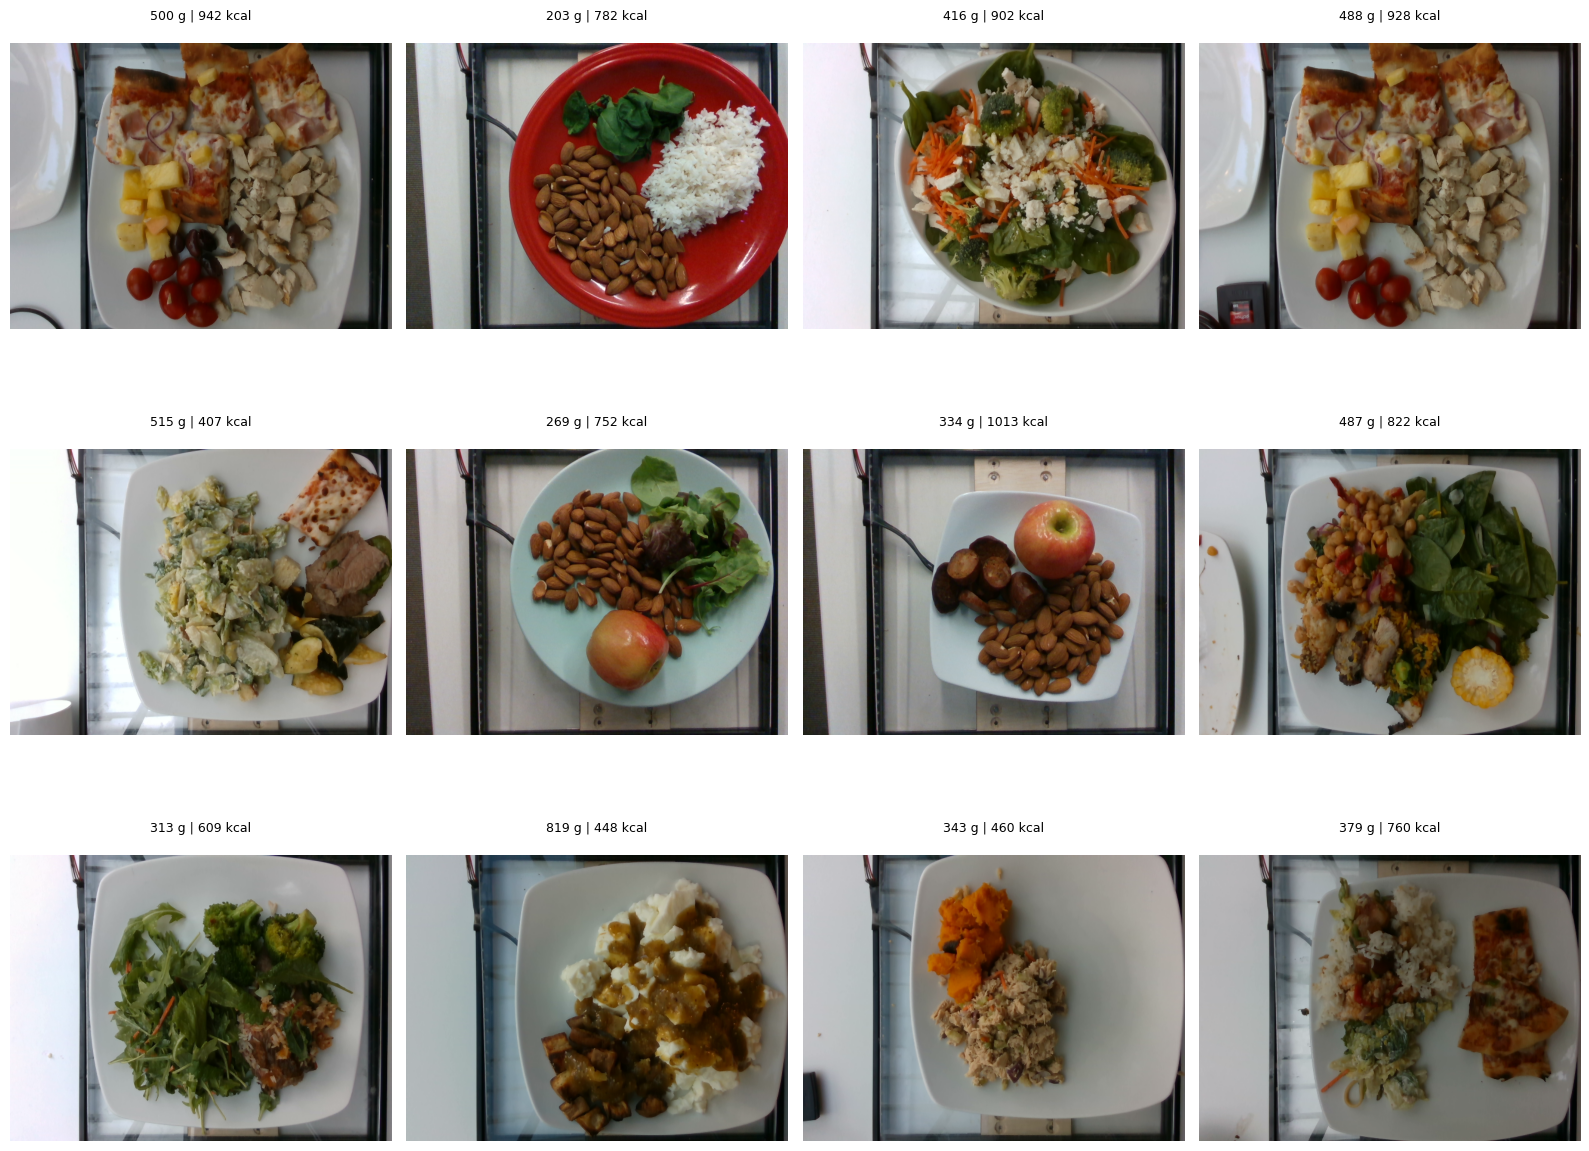

In [37]:
show_dishes(err_df.nlargest(12, "abs_err"))

In [38]:
err_df.nlargest(12, "abs_err")

,dish_id,total_calories,total_mass,ingredients,pred_kcal,abs_err
76,dish_1566328831,941.609985,500.0,"pizza, cherry tomatoes, chicken, pineapple, ol...",587.463440,354.146545
298,dish_1558549806,781.958008,203.0,"almonds, white rice, spinach (raw)",437.400665,344.557343
141,dish_1565811139,902.200012,416.0,"carrot, goat cheese, olive oil, broccoli, spin...",558.215393,343.984619
86,dish_1566328805,927.809998,488.0,"cherry tomatoes, pizza, chicken, pineapple",622.677368,305.132630
244,dish_1565123881,406.821747,515.0,"caesar salad, olive oil, onions, cheese pizza,...",662.722229,255.900482
171,dish_1558630325,751.541992,269.0,"apple, garden salad, almonds",506.103180,245.438812
54,dish_1558373159,1013.337036,334.0,"sausage, , almonds",775.461853,237.875183
31,dish_1566502573,821.510193,487.0,"chive, bok choy, chicken, white rice, pork, ar...",611.427673,210.082520
302,dish_1565030391,609.333923,313.0,"white rice, garlic, orange juice, onions, cucu...",409.029510,200.304413
95,dish_1566316757,448.382874,819.0,"sweet potato, egg whites, olive oil, salsa",647.413635,199.030761


Глядя на самые ошибочные блюда видим, что ошибка в основном не из-за модели, а нехватка информации во входе, список ингридиентов говорит, что есть в блюде, но не говорить сколько каждого ингридиента. Поэтому для ошибочных блюд с точки зрения модели предсказания "средние", как у большинства блюд. В MAE при этом доминируют высококалорийные блюда. Так как их мало, модель не смогла выучить наличие таких блюд, и при неуверенности сдвигалась к среднему значению.

Отсюда и обратная ошибка - переоценка. В составе есть pizza и olieve oil, но их немного, модель поднимает прогноз, а блюдо в основном из овощей. Также при сборке test датасета виден баг ` sausage, , almonds`. У dish_1558373159 средний ингредиент — deprecated. Вместо удаления он стал пустой строкой, и в тексте осталось ", ,". Так быть не должно. Плюс модель не знает, что пропал целый ингредиент, а это блюдо с самой высокой калорийностью в списке (1013 ккал).


Таким образом, модели необходимо большее разрешение фотографий на вход, чтобы она смогла разгляждеть количество ингридиентов